# UK Gender Pay Gap: predicting an employer's gap from its size, industry and region
**Author:** Nick

**Question:** what is the predicted gender pay gap for companies given employer size, industry and region?

**Dataset:** `UK_GenderPayGap_NoYears (revised).csv`. Each row is one employer, with its reported figures averaged across the years it filed.

- **Target:** `DiffMedianHourlyPercent`, the employer's median hourly pay gap. Positive values mean men earn more than women; negative values mean women earn more.
- **Predictors:** `Size`, `Industry` and `Region` only, as set by the question.
- **Settings from the project brief:** 80/20 train-test split and 5-fold cross-validation.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)
sns.set_theme(style="whitegrid")

# The CSV sits in the repo root, one level up from the Nick/ folder
df = pd.read_csv("../UK_GenderPayGap_NoYears (revised).csv")
df.columns = [c.replace("Average of ", "") for c in df.columns]   # drop the pivot-table prefix

target = "DiffMedianHourlyPercent"
predictors = ["Size", "Industry", "Region"]
data = df[predictors + [target]]
print(data.shape)
print(data.isna().sum())
data.head()

(12748, 4)
Size                       0
Industry                   0
Region                     0
DiffMedianHourlyPercent    0
dtype: int64


,Size,Industry,Region,DiffMedianHourlyPercent
0,500 to 999,Health/SocialWork,Southampton,-5.440
1,250 to 499,Manufacturing,Leicester,6.475
2,1000 to 4999,AdministrativeServices,Bristol,9.475
3,250 to 499,Manufacturing,Stockport,-5.220
4,500 to 999,Wholesale & Retail Trade,Reading,4.460


In [2]:
# How many categories each predictor has
for col in predictors:
    print(f"{col}: {data[col].nunique()} categories")
data["Size"].value_counts()

Size: 7 categories
Industry: 19 categories
Region: 120 categories


Size
250 to 499        6172
500 to 999        2939
1000 to 4999      2453
Less than 250      584
5000 to 19,999     507
20,000 or more      63
Not Provided        30
Name: count, dtype: int64

**Data notes**
- No values are missing in the target or the predictors, so all 12,748 employers are used.
- **Size** has 7 bands, including "Not Provided" (30 employers). **Industry** has 19, including "Unknown" (about 1,300 employers). Both are kept as categories of their own.
- **Region** has 120 values (postcode areas such as Central London or Birmingham). A few have only 1 to 20 employers, so their averages are unreliable.

## 1. Heat map: average gap by industry and size

All three predictors are categories, so a correlation matrix doesn't apply. Instead, the heat map shows the **median gap** for each combination of industry and size. Cells with fewer than 10 employers are left blank, because their medians are unreliable.

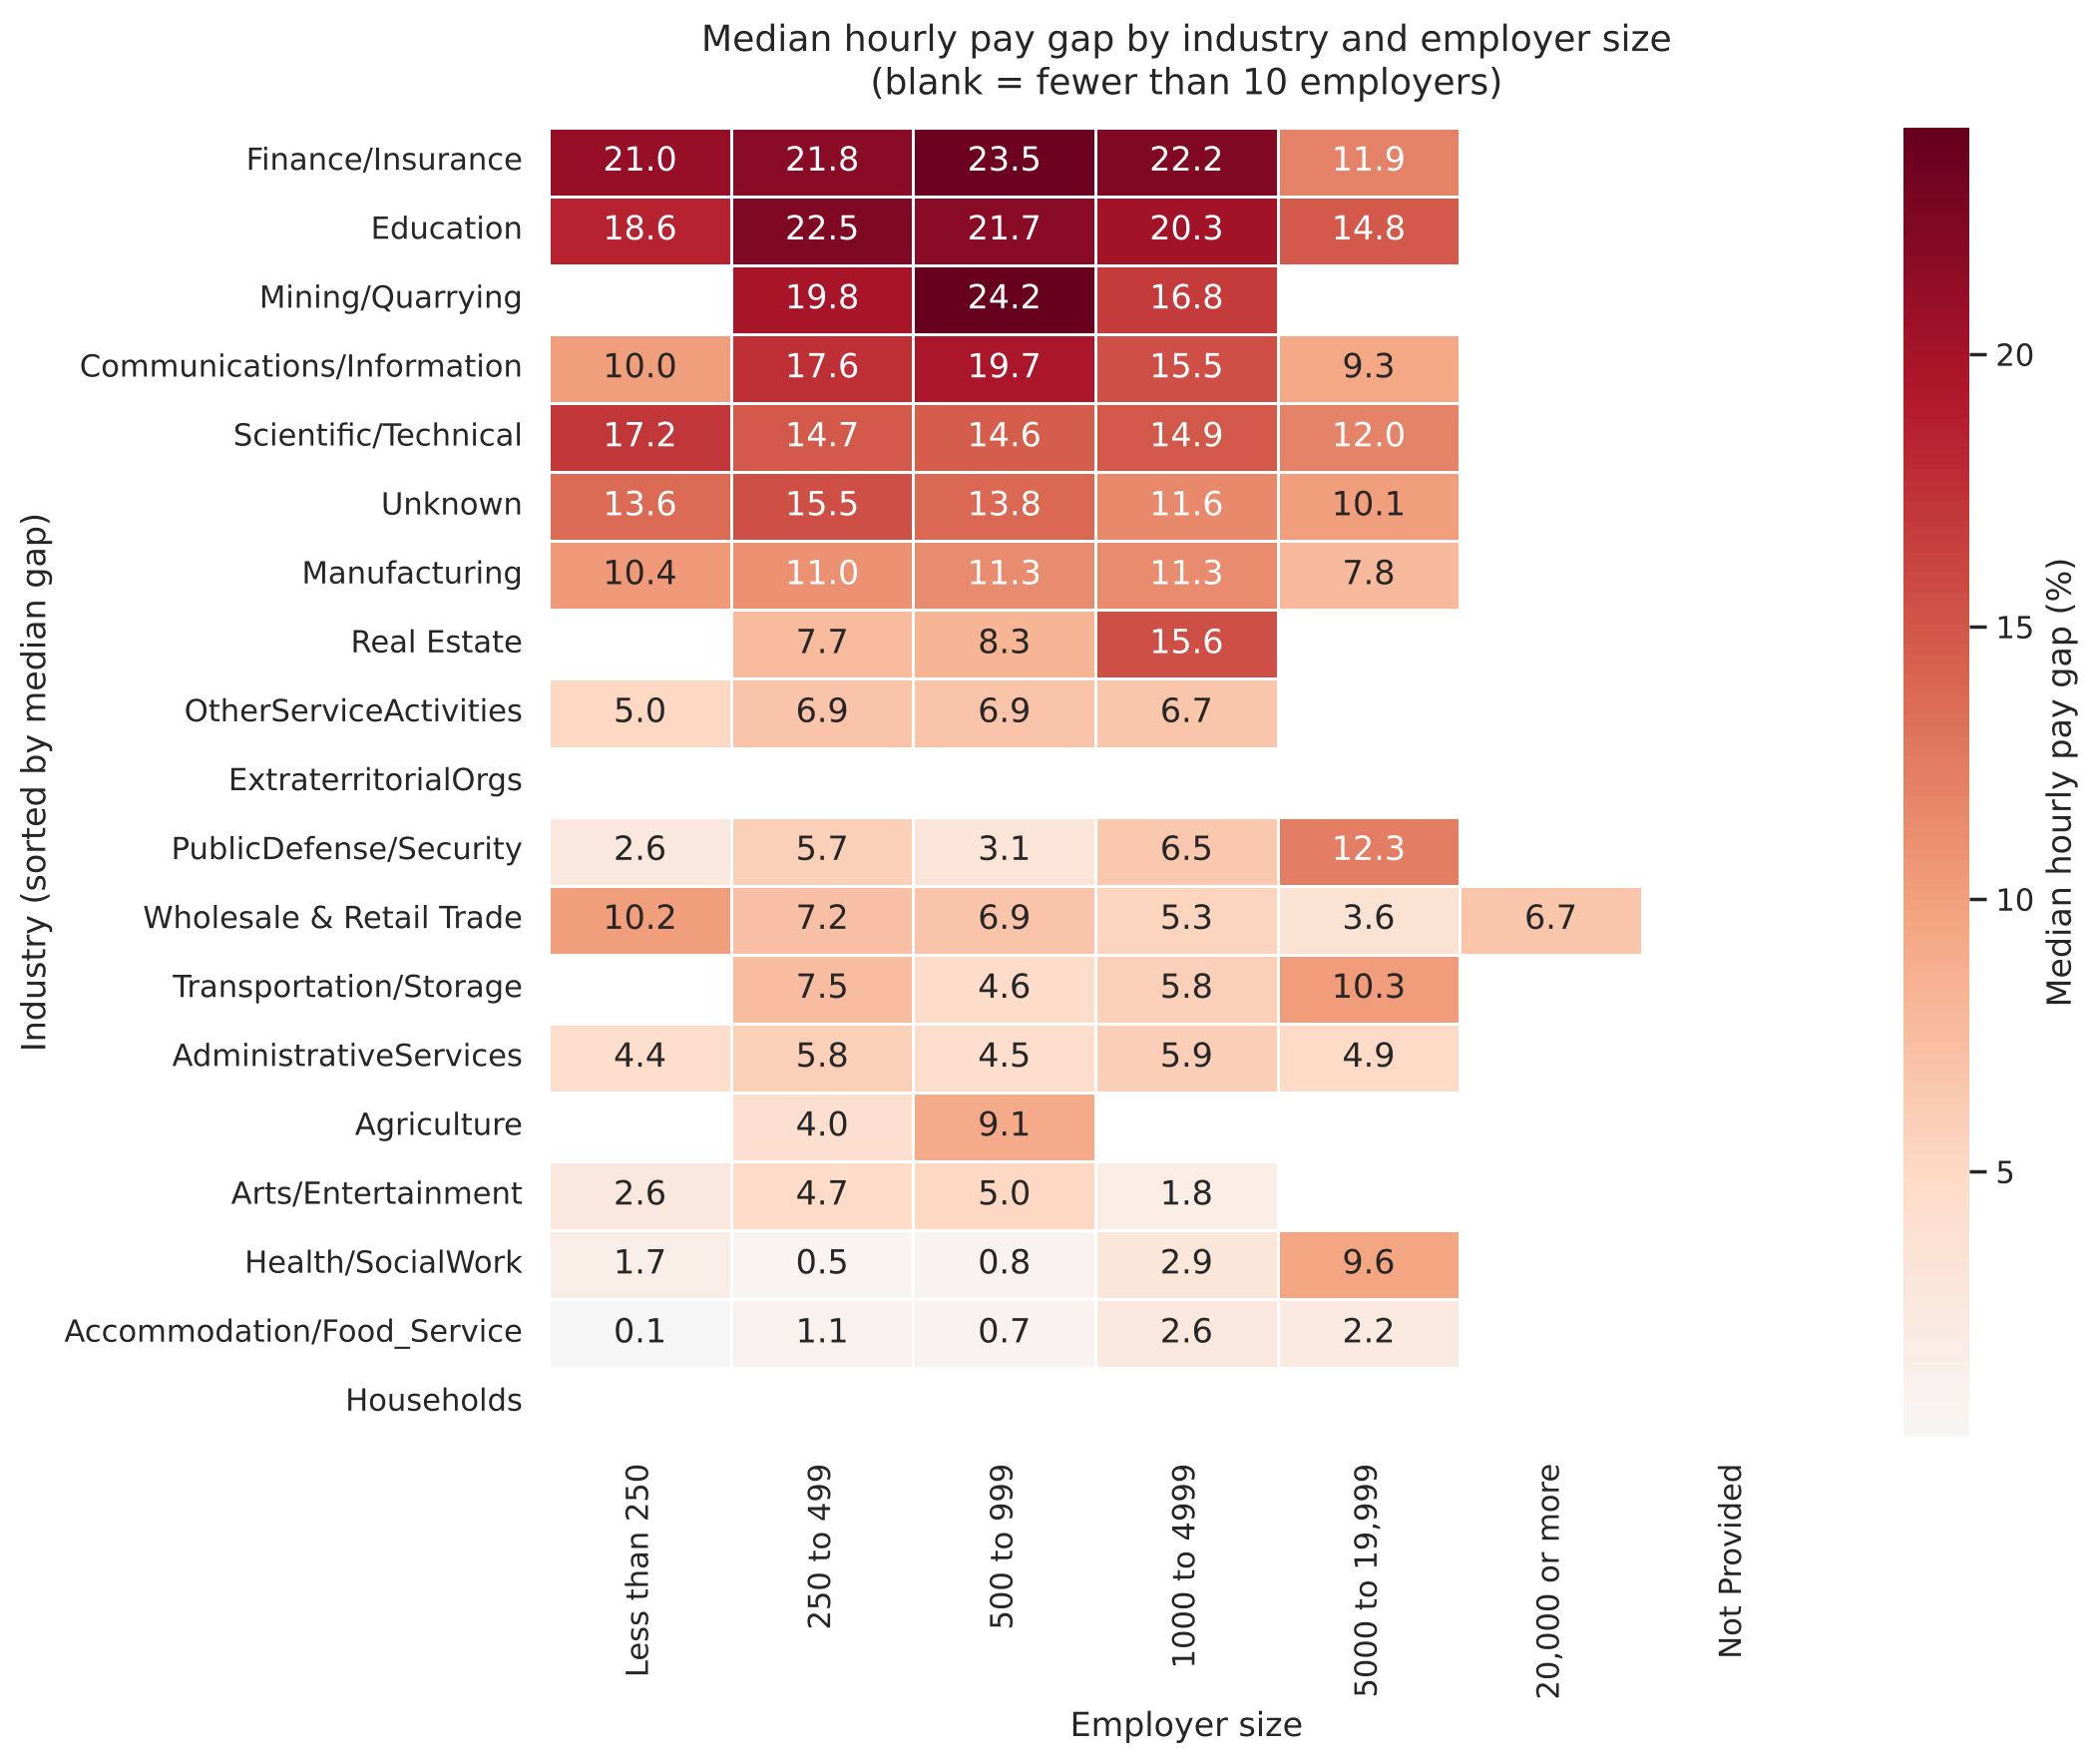

In [3]:
size_order = ["Less than 250", "250 to 499", "500 to 999", "1000 to 4999",
              "5000 to 19,999", "20,000 or more", "Not Provided"]
industry_order = data.groupby("Industry")[target].median().sort_values(ascending=False).index

median_gap = data.pivot_table(index="Industry", columns="Size", values=target, aggfunc="median")
counts = data.pivot_table(index="Industry", columns="Size", values=target, aggfunc="count")
median_gap = median_gap.loc[industry_order, size_order]
counts = counts.reindex(index=industry_order, columns=size_order)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(median_gap, mask=(counts.isna() | (counts < 10)), annot=True, fmt=".1f",
            cmap="RdBu_r", center=0, linewidths=0.5,
            cbar_kws={"label": "Median hourly pay gap (%)"}, ax=ax)
ax.grid(False)
ax.set_xlabel("Employer size")
ax.set_ylabel("Industry (sorted by median gap)")
ax.set_title("Median hourly pay gap by industry and employer size\n(blank = fewer than 10 employers)",
             fontsize=13, pad=12)
plt.tight_layout()
plt.show()

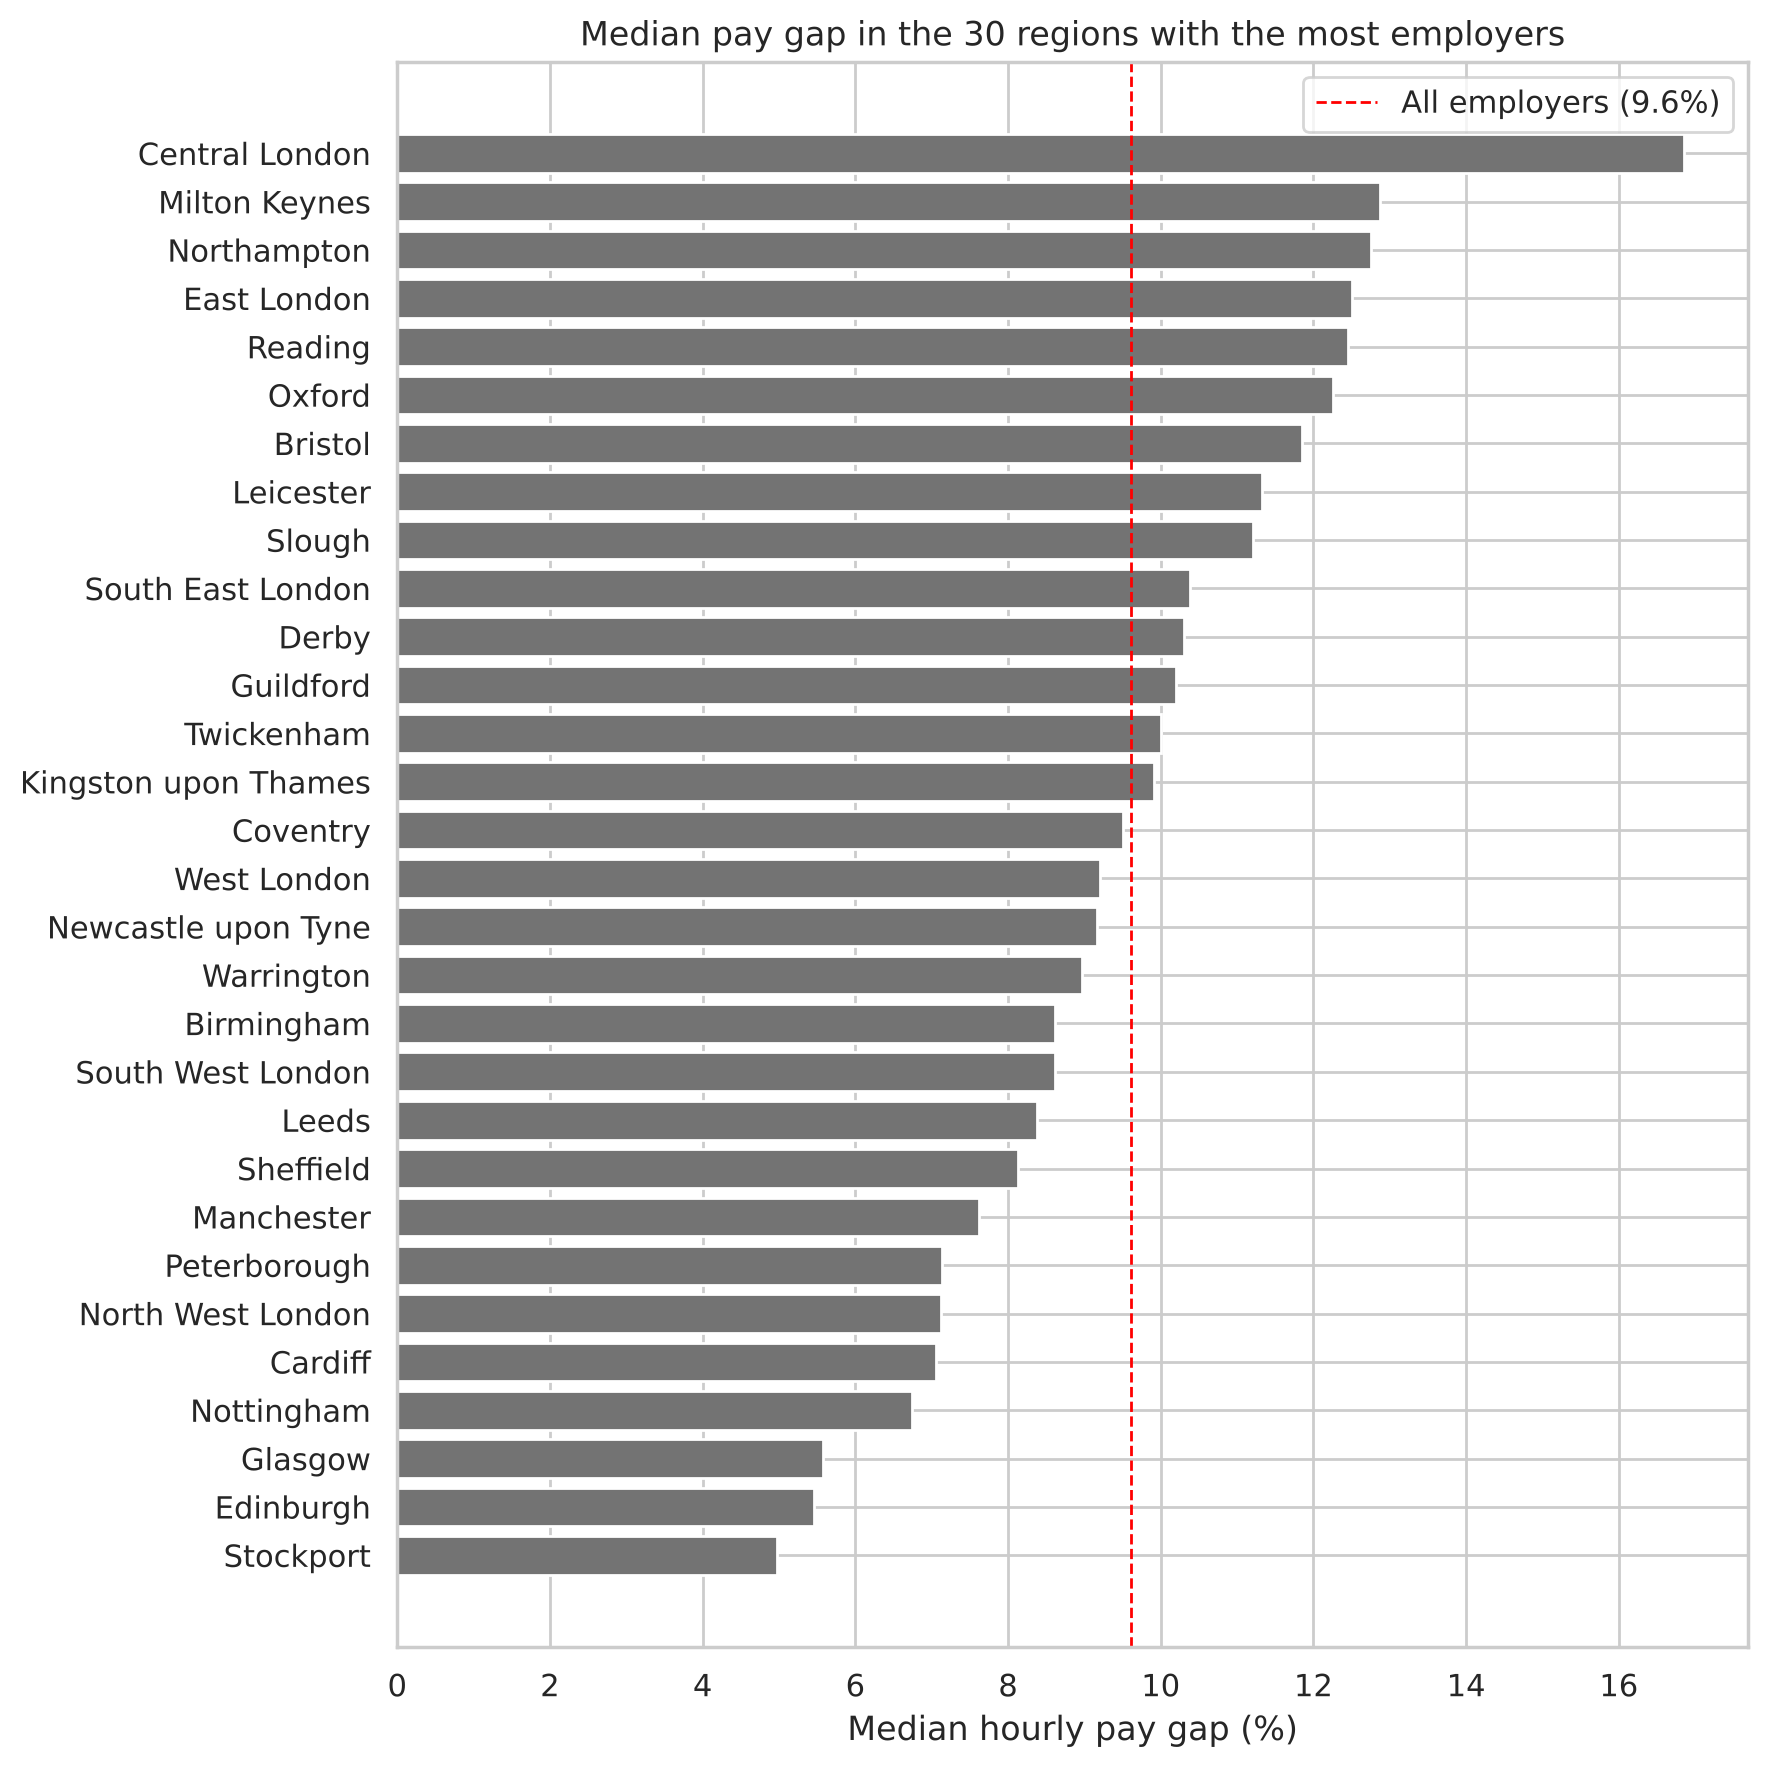

In [4]:
# Median gap by region, for the 30 regions with the most employers
top_regions = data["Region"].value_counts().head(30).index
region_gap = (data[data["Region"].isin(top_regions)]
              .groupby("Region")[target].agg(employers="count", median_gap="median")
              .sort_values("median_gap"))

fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(region_gap.index, region_gap["median_gap"], color="0.45")
ax.axvline(data[target].median(), color="red", linestyle="--", linewidth=1,
           label=f"All employers ({data[target].median():.1f}%)")
ax.set_xlabel("Median hourly pay gap (%)")
ax.set_title("Median pay gap in the 30 regions with the most employers")
ax.legend()
plt.tight_layout()
plt.show()

In [5]:
# Share of the variation in gaps that each predictor's category averages account for
total = ((data[target] - data[target].mean()) ** 2).sum()
explained = {}
for col in predictors:
    group_mean = data.groupby(col)[target].transform("mean")
    explained[col] = 1 - ((data[target] - group_mean) ** 2).sum() / total
pd.Series(explained, name="share of variation explained").round(3)

Size        0.002
Industry    0.130
Region      0.033
Name: share of variation explained, dtype: float64

### What the heat map and charts show
- **Industry matters most.** Median gaps run from about 1% in Accommodation/Food Service and Health/Social Work to over 20% in Finance/Insurance and Education. Industry averages alone account for about **13%** of the variation in gaps.
- **Region matters a little.** London areas tend to have larger gaps than the rest of the country, but region accounts for only about **3%** of the variation. Part of that is probably industry: finance firms cluster in Central London.
- **Size barely matters** (0.2%). Within an industry, the gap moves little from one size band to the next, with no consistent direction.
- **Most of the variation is within groups.** Two employers in the same industry, size band and region can have very different gaps, so these three predictors can only give a rough expectation for any one company.
- Some cells are blank: very large employers (20,000 or more), "Not Provided" sizes, and the two smallest industries (Households and Extraterritorial Orgs) have too few employers per cell.

## 2. Modelling setup

- **Encoding:** each predictor becomes a set of 0/1 dummy columns with `OneHotEncoder` (Lab 4 uses `pd.get_dummies` for the same thing). That gives about 146 columns. `handle_unknown="ignore"` covers a rare region that appears in a test fold but not in its training rows.
- **Split:** 80% train, 20% test, with 5-fold cross-validation on the training set for all tuning. The test set is used once, at the end.
- **Metrics:**
  - R²: the share of the variation in gaps explained (0 = no better than predicting the average).
  - MAE: the average error, in percentage points.
  - RMSE: like MAE, but errors are squared before averaging, so large misses count more.
- **Benchmarks:**
  - always predicting the training average (`DummyRegressor`)
  - predicting each employer's **industry average**, a simple lookup a certification body could do without a model
  - linear regression on the same dummies

In [6]:
X = data[predictors]
y = data[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
folds = KFold(n_splits=5, shuffle=True, random_state=42)
print("Train:", len(X_train), "| Test:", len(X_test))

def encoder():
    return OneHotEncoder(handle_unknown="ignore", sparse_output=False)

def test_scores(pred):
    return {"test R²": r2_score(y_test, pred),
            "test MAE": mean_absolute_error(y_test, pred),
            "test RMSE": np.sqrt(mean_squared_error(y_test, pred))}

# Benchmarks
base_pred = DummyRegressor().fit(X_train, y_train).predict(X_test)
industry_means = y_train.groupby(X_train["Industry"]).mean()
industry_pred = X_test["Industry"].map(industry_means).fillna(y_train.mean())

lr = make_pipeline(encoder(), LinearRegression())
lr_cv = cross_val_score(lr, X_train, y_train, cv=folds, scoring="r2").mean()
lr_pred = lr.fit(X_train, y_train).predict(X_test)

benchmarks = pd.DataFrame({
    "Training average": test_scores(base_pred),
    "Industry average": test_scores(industry_pred),
    "Linear regression": test_scores(lr_pred),
}).T
benchmarks["CV R²"] = [np.nan, np.nan, lr_cv]
benchmarks.round(3)

Train: 10198 | Test: 2550


,test R²,test MAE,test RMSE,CV R²
Training average,-0.00,11.726,15.831,NaN
Industry average,0.12,10.523,14.849,NaN
Linear regression,0.12,10.493,14.850,0.128


## 3. kNN

The dummies are already all 0 or 1, so no further scaling is needed. Two employers are close when they share a size band, an industry and a region. We tune the number of neighbours `k` and the weighting with 5-fold CV.

In [7]:
knn_grid = {"kneighborsregressor__n_neighbors": [5, 11, 21, 51, 101, 201, 301],
            "kneighborsregressor__weights": ["uniform", "distance"]}
knn_search = GridSearchCV(make_pipeline(encoder(), KNeighborsRegressor()),
                          knn_grid, cv=folds, scoring="r2").fit(X_train, y_train)
knn_pred = knn_search.predict(X_test)
print("Best settings:", knn_search.best_params_)
print("CV R²:", round(knn_search.best_score_, 3))
print("Test R²:", round(r2_score(y_test, knn_pred), 3),
      "| MAE:", round(mean_absolute_error(y_test, knn_pred), 2),
      "| RMSE:", round(np.sqrt(mean_squared_error(y_test, knn_pred)), 2))

Best settings: {'kneighborsregressor__n_neighbors': 101, 'kneighborsregressor__weights': 'uniform'}
CV R²: 0.129
Test R²: 0.122 | MAE: 10.64 | RMSE: 14.83


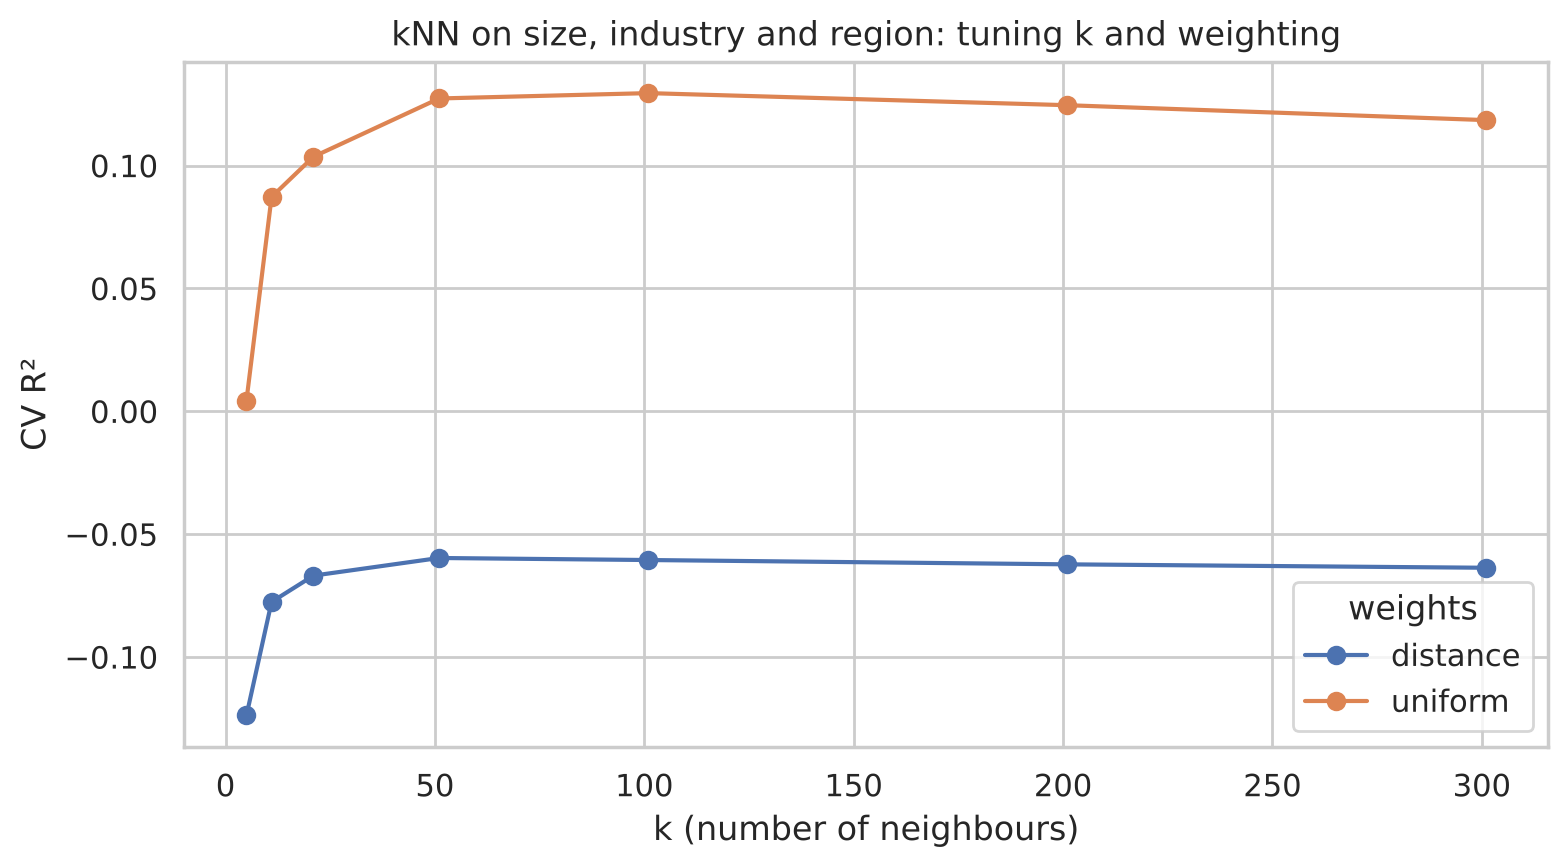

In [8]:
# How the CV score changes with k
cv_k = pd.DataFrame(knn_search.cv_results_).pivot(
    index="param_kneighborsregressor__n_neighbors",
    columns="param_kneighborsregressor__weights", values="mean_test_score")
ax = cv_k.plot(marker="o", figsize=(8, 4.5))
ax.set_xlabel("k (number of neighbours)")
ax.set_ylabel("CV R²")
ax.set_title("kNN on size, industry and region: tuning k and weighting")
ax.legend(title="weights")
plt.tight_layout()
plt.show()

**kNN explains about 12% of the variation in gaps on the test set** (CV R² 0.129, test R² 0.122, MAE 10.6 points, RMSE 14.8 points). The best `k` is large (101), so each prediction averages many similar employers, which is close to taking the average for that industry. This makes sense: with only three categories, many employers have exactly the same predictors, and kNN can do little more than average them.

## 4. Neural network

**Procedure (Lab 8 and the Session 16 slides)**
1. The inputs are the same 0/1 dummies, already on a 0–1 scale.
2. **The target is scaled to 0–1** with `MinMaxScaler`, fit on the training rows only, and predictions are converted back to percentage points with `inverse_transform`. (R² is the same on either scale.)
3. **`MLPRegressor`** with `solver='lbfgs'`, `tol=1e-8` and `max_iter=2000` (the lab's fix for networks that stop training too early).
4. **Tune three hyperparameters with 5-fold CV:** `hidden_layer_sizes`, `activation` (logistic or ReLU) and `alpha` (regularization, which shrinks the weights to curb overfitting). With about 146 dummy columns there is plenty of room to overfit, so `alpha` matters here.
5. **Check the starting weights** by re-running with other `random_state` values (Lab 8, Exercise 2).
6. **Test once.**

In [9]:
scaleOutput = MinMaxScaler()
y_train_scaled = scaleOutput.fit_transform(y_train.to_frame()).ravel()

def to_gap(scaled_predictions):
    """Undo the 0-1 scaling so predictions are back in percentage points."""
    return scaleOutput.inverse_transform(np.asarray(scaled_predictions).reshape(-1, 1)).ravel()

def nn_pipeline(random_state=1, **params):
    return make_pipeline(encoder(),
                         MLPRegressor(solver="lbfgs", tol=1e-8, max_iter=2000,
                                      random_state=random_state, **params))

nn_grid = {"mlpregressor__hidden_layer_sizes": [(2,), (5,), (10,), (5, 5), (10, 10)],
           "mlpregressor__activation": ["logistic", "relu"],
           "mlpregressor__alpha": [0.01, 0.1, 1, 10]}

nn_search = GridSearchCV(nn_pipeline(), nn_grid, cv=folds, scoring="r2", n_jobs=-1)
nn_search.fit(X_train, y_train_scaled)
best_params = {k.replace("mlpregressor__", ""): v for k, v in nn_search.best_params_.items()}
print("Best settings:", best_params)
print("CV R²:", round(nn_search.best_score_, 3))

Best settings: {'activation': 'logistic', 'alpha': 1, 'hidden_layer_sizes': (10,)}
CV R²: 0.135


In [10]:
# CV R² for each architecture and activation, at its best alpha
res = pd.DataFrame(nn_search.cv_results_)
res["hidden layers"] = res["param_mlpregressor__hidden_layer_sizes"].astype(str)
print("Best alpha for each architecture and activation:")
print(res.loc[res.groupby(["hidden layers", "param_mlpregressor__activation"])["mean_test_score"].idxmax(),
              ["hidden layers", "param_mlpregressor__activation", "param_mlpregressor__alpha",
               "mean_test_score"]].round(3).to_string(index=False))

Best alpha for each architecture and activation:
hidden layers param_mlpregressor__activation  param_mlpregressor__alpha  mean_test_score
     (10, 10)                       logistic                       0.10            0.134
     (10, 10)                           relu                       1.00            0.135
        (10,)                       logistic                       1.00            0.135
        (10,)                           relu                       1.00            0.134
         (2,)                       logistic                       1.00            0.135
         (2,)                           relu                       1.00            0.079
       (5, 5)                       logistic                       0.10            0.134
       (5, 5)                           relu                       0.01            0.126
         (5,)                       logistic                       1.00            0.135
         (5,)                           relu                 

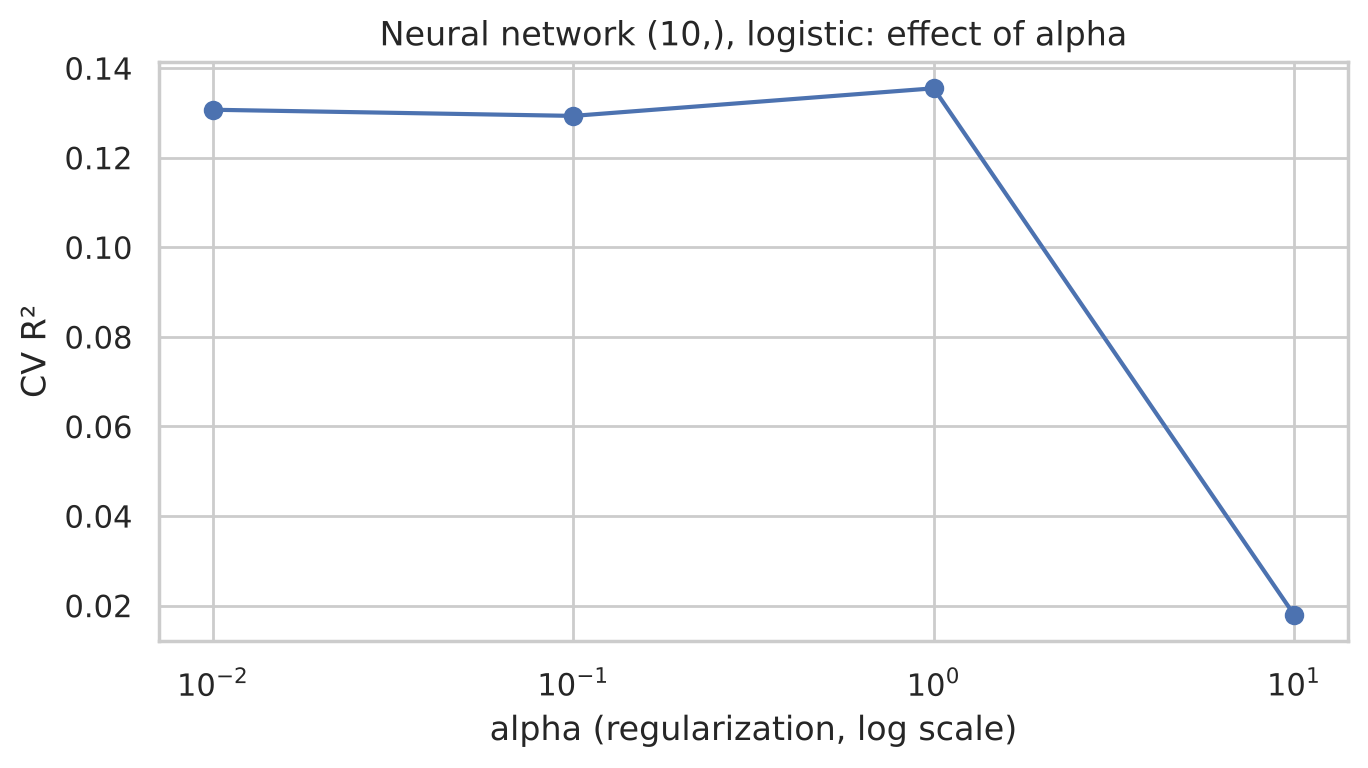

In [11]:
# CV R² by alpha for the best architecture: too little regularization overfits
best_arch = res[(res["param_mlpregressor__hidden_layer_sizes"] == best_params["hidden_layer_sizes"]) &
                (res["param_mlpregressor__activation"] == best_params["activation"])]
ax = best_arch.plot(x="param_mlpregressor__alpha", y="mean_test_score", marker="o", logx=True,
                    legend=False, figsize=(7, 4))
ax.set_xlabel("alpha (regularization, log scale)")
ax.set_ylabel("CV R²")
ax.set_title(f"Neural network {best_params['hidden_layer_sizes']}, {best_params['activation']}: effect of alpha")
plt.tight_layout()
plt.show()

**What the tuning shows**
- **Every architecture lands at about the same score** (CV R² 0.13 to 0.135), so a small network is enough. The best is one hidden layer of 10 logistic nodes, but networks with 2, 5 or 10 nodes score the same within 0.001.
- **Regularization matters.** The best networks use a fairly large `alpha` (1). With little regularization, the network starts fitting the many rare regions and does worse.
- **Failed attempt:** a single layer of 2 ReLU nodes scores only 0.079, because some of its nodes switch off during training.

### 4.1 Do the starting weights matter?

In [12]:
seed_rows = []
for seed in range(1, 6):
    model = nn_pipeline(random_state=seed, **best_params)
    cv = cross_val_score(model, X_train, y_train_scaled, cv=folds, scoring="r2", n_jobs=-1).mean()
    pred = to_gap(model.fit(X_train, y_train_scaled).predict(X_test))
    seed_rows.append({"random_state": seed, "CV R²": cv, **test_scores(pred)})
seeds = pd.DataFrame(seed_rows).set_index("random_state")
print(seeds.round(3))
seeds.agg(["mean", "min", "max"]).round(3)

              CV R²  test R²  test MAE  test RMSE
random_state                                     
1             0.135    0.126    10.487     14.802
2             0.136    0.125    10.494     14.809
3             0.136    0.126    10.489     14.801
4             0.135    0.126    10.495     14.801
5             0.135    0.125    10.501     14.810


,CV R²,test R²,test MAE,test RMSE
mean,0.135,0.125,10.493,14.804
min,0.135,0.125,10.487,14.801
max,0.136,0.126,10.501,14.810


**The starting weights don't matter here:** across five starting points, test R² stays at 0.125 to 0.126. The strong regularization keeps the network stable.

## 5. Results

In [13]:
final_nn = nn_pipeline(random_state=1, **best_params).fit(X_train, y_train_scaled)
nn_pred = to_gap(final_nn.predict(X_test))

comparison = pd.concat([benchmarks, pd.DataFrame({
    f"kNN (k={knn_search.best_params_['kneighborsregressor__n_neighbors']}, "
    f"{knn_search.best_params_['kneighborsregressor__weights']})": {**test_scores(knn_pred), "CV R²": knn_search.best_score_},
    f"Neural network {best_params['hidden_layer_sizes']}, {best_params['activation']}, "
    f"alpha={best_params['alpha']}": {**test_scores(nn_pred), "CV R²": nn_search.best_score_},
}).T])
comparison.round(3)

,test R²,test MAE,test RMSE,CV R²
Training average,-0.000,11.726,15.831,NaN
Industry average,0.120,10.523,14.849,NaN
Linear regression,0.120,10.493,14.850,0.128
"kNN (k=101, uniform)",0.122,10.637,14.835,0.129
"Neural network (10,), logistic, alpha=1",0.126,10.487,14.802,0.135


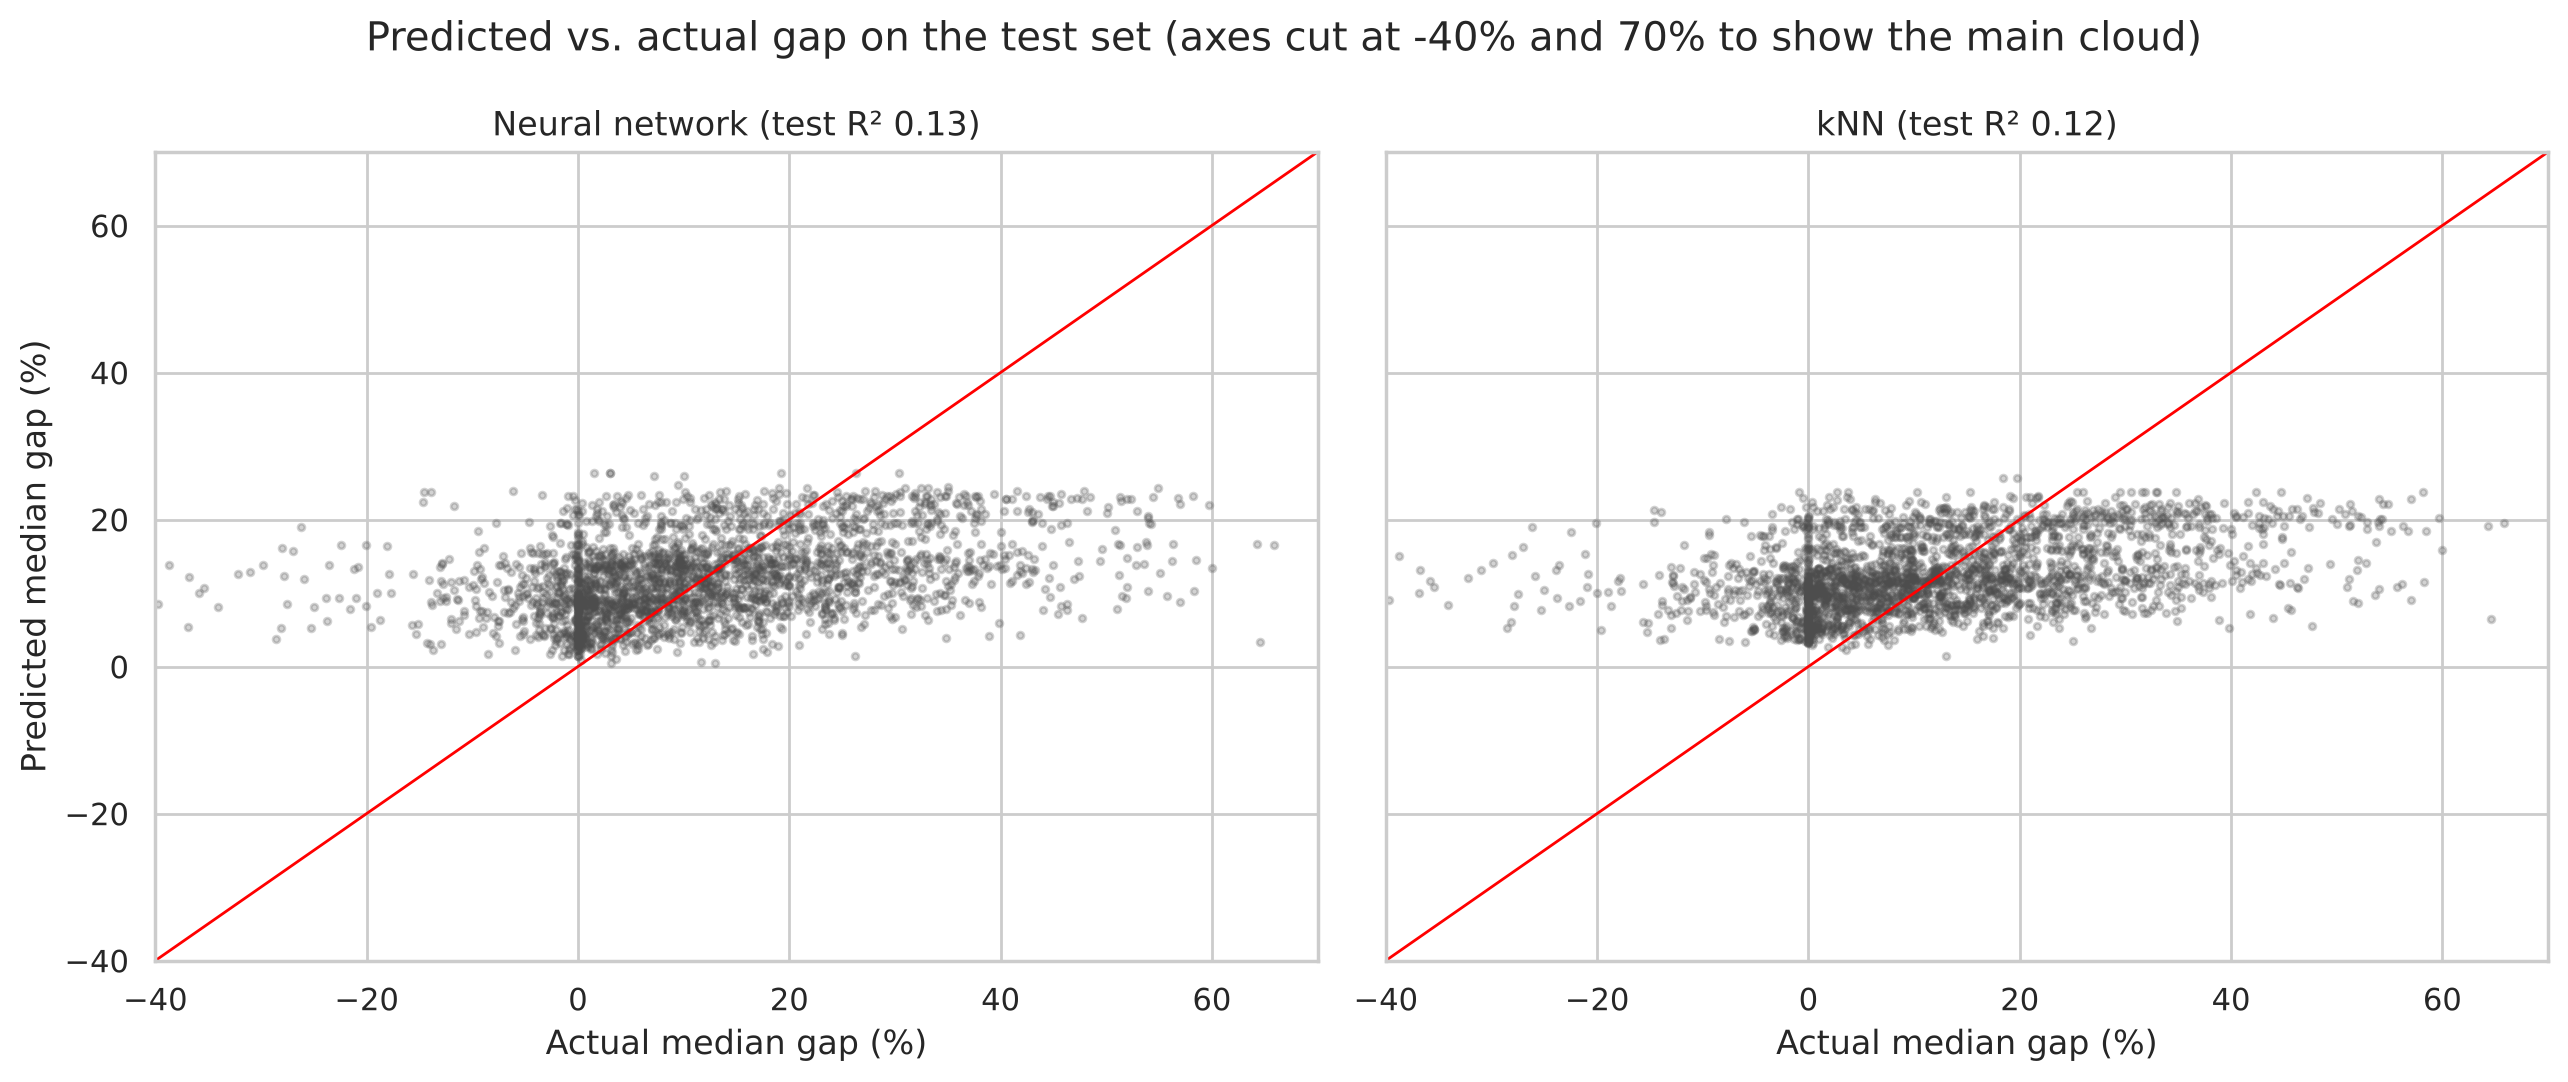

In [14]:
# Predicted vs. actual gap on the test set (a perfect model puts every employer on the diagonal)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)
for ax, pred, title in [(axes[0], nn_pred, "Neural network"), (axes[1], knn_pred, "kNN")]:
    ax.scatter(y_test, pred, s=6, alpha=0.25, color="0.3")
    ax.plot([-40, 70], [-40, 70], color="red", linewidth=1)
    ax.set_xlim(-40, 70)
    ax.set_ylim(-40, 70)
    ax.set_title(f"{title} (test R² {r2_score(y_test, pred):.2f})")
    ax.set_xlabel("Actual median gap (%)")
axes[0].set_ylabel("Predicted median gap (%)")
plt.suptitle("Predicted vs. actual gap on the test set (axes cut at -40% and 70% to show the main cloud)")
plt.tight_layout()
plt.show()

### 5.1 What drives the predictions?

Neither model has a feature importance of its own. Instead, we drop one predictor at a time, re-run 5-fold CV with the same settings, and see how much the score falls. (This is to explain the models, not to choose predictors: the question fixes all three.)

In [15]:
drop_rows = []
for dropped in predictors:
    keep = [p for p in predictors if p != dropped]
    knn_cv = cross_val_score(make_pipeline(encoder(), KNeighborsRegressor(
        n_neighbors=knn_search.best_params_["kneighborsregressor__n_neighbors"],
        weights=knn_search.best_params_["kneighborsregressor__weights"])),
        X_train[keep], y_train, cv=folds, scoring="r2").mean()
    nn_cv = cross_val_score(nn_pipeline(random_state=1, **best_params), X_train[keep], y_train_scaled,
                            cv=folds, scoring="r2", n_jobs=-1).mean()
    drop_rows.append({"predictor dropped": dropped,
                      "kNN: fall in CV R²": knn_search.best_score_ - knn_cv,
                      "neural net: fall in CV R²": nn_search.best_score_ - nn_cv})
pd.DataFrame(drop_rows).set_index("predictor dropped").round(3)

,kNN: fall in CV R²,neural net: fall in CV R²
predictor dropped,,
Size,-0.003,-0.00
Industry,0.120,0.12
Region,0.010,0.01


### 5.2 Predicted gap by industry and size

This answers the question directly: the neural network's predicted median gap for each industry and size band. Each cell averages the predictions across all regions, weighted by how many employers are in each region.

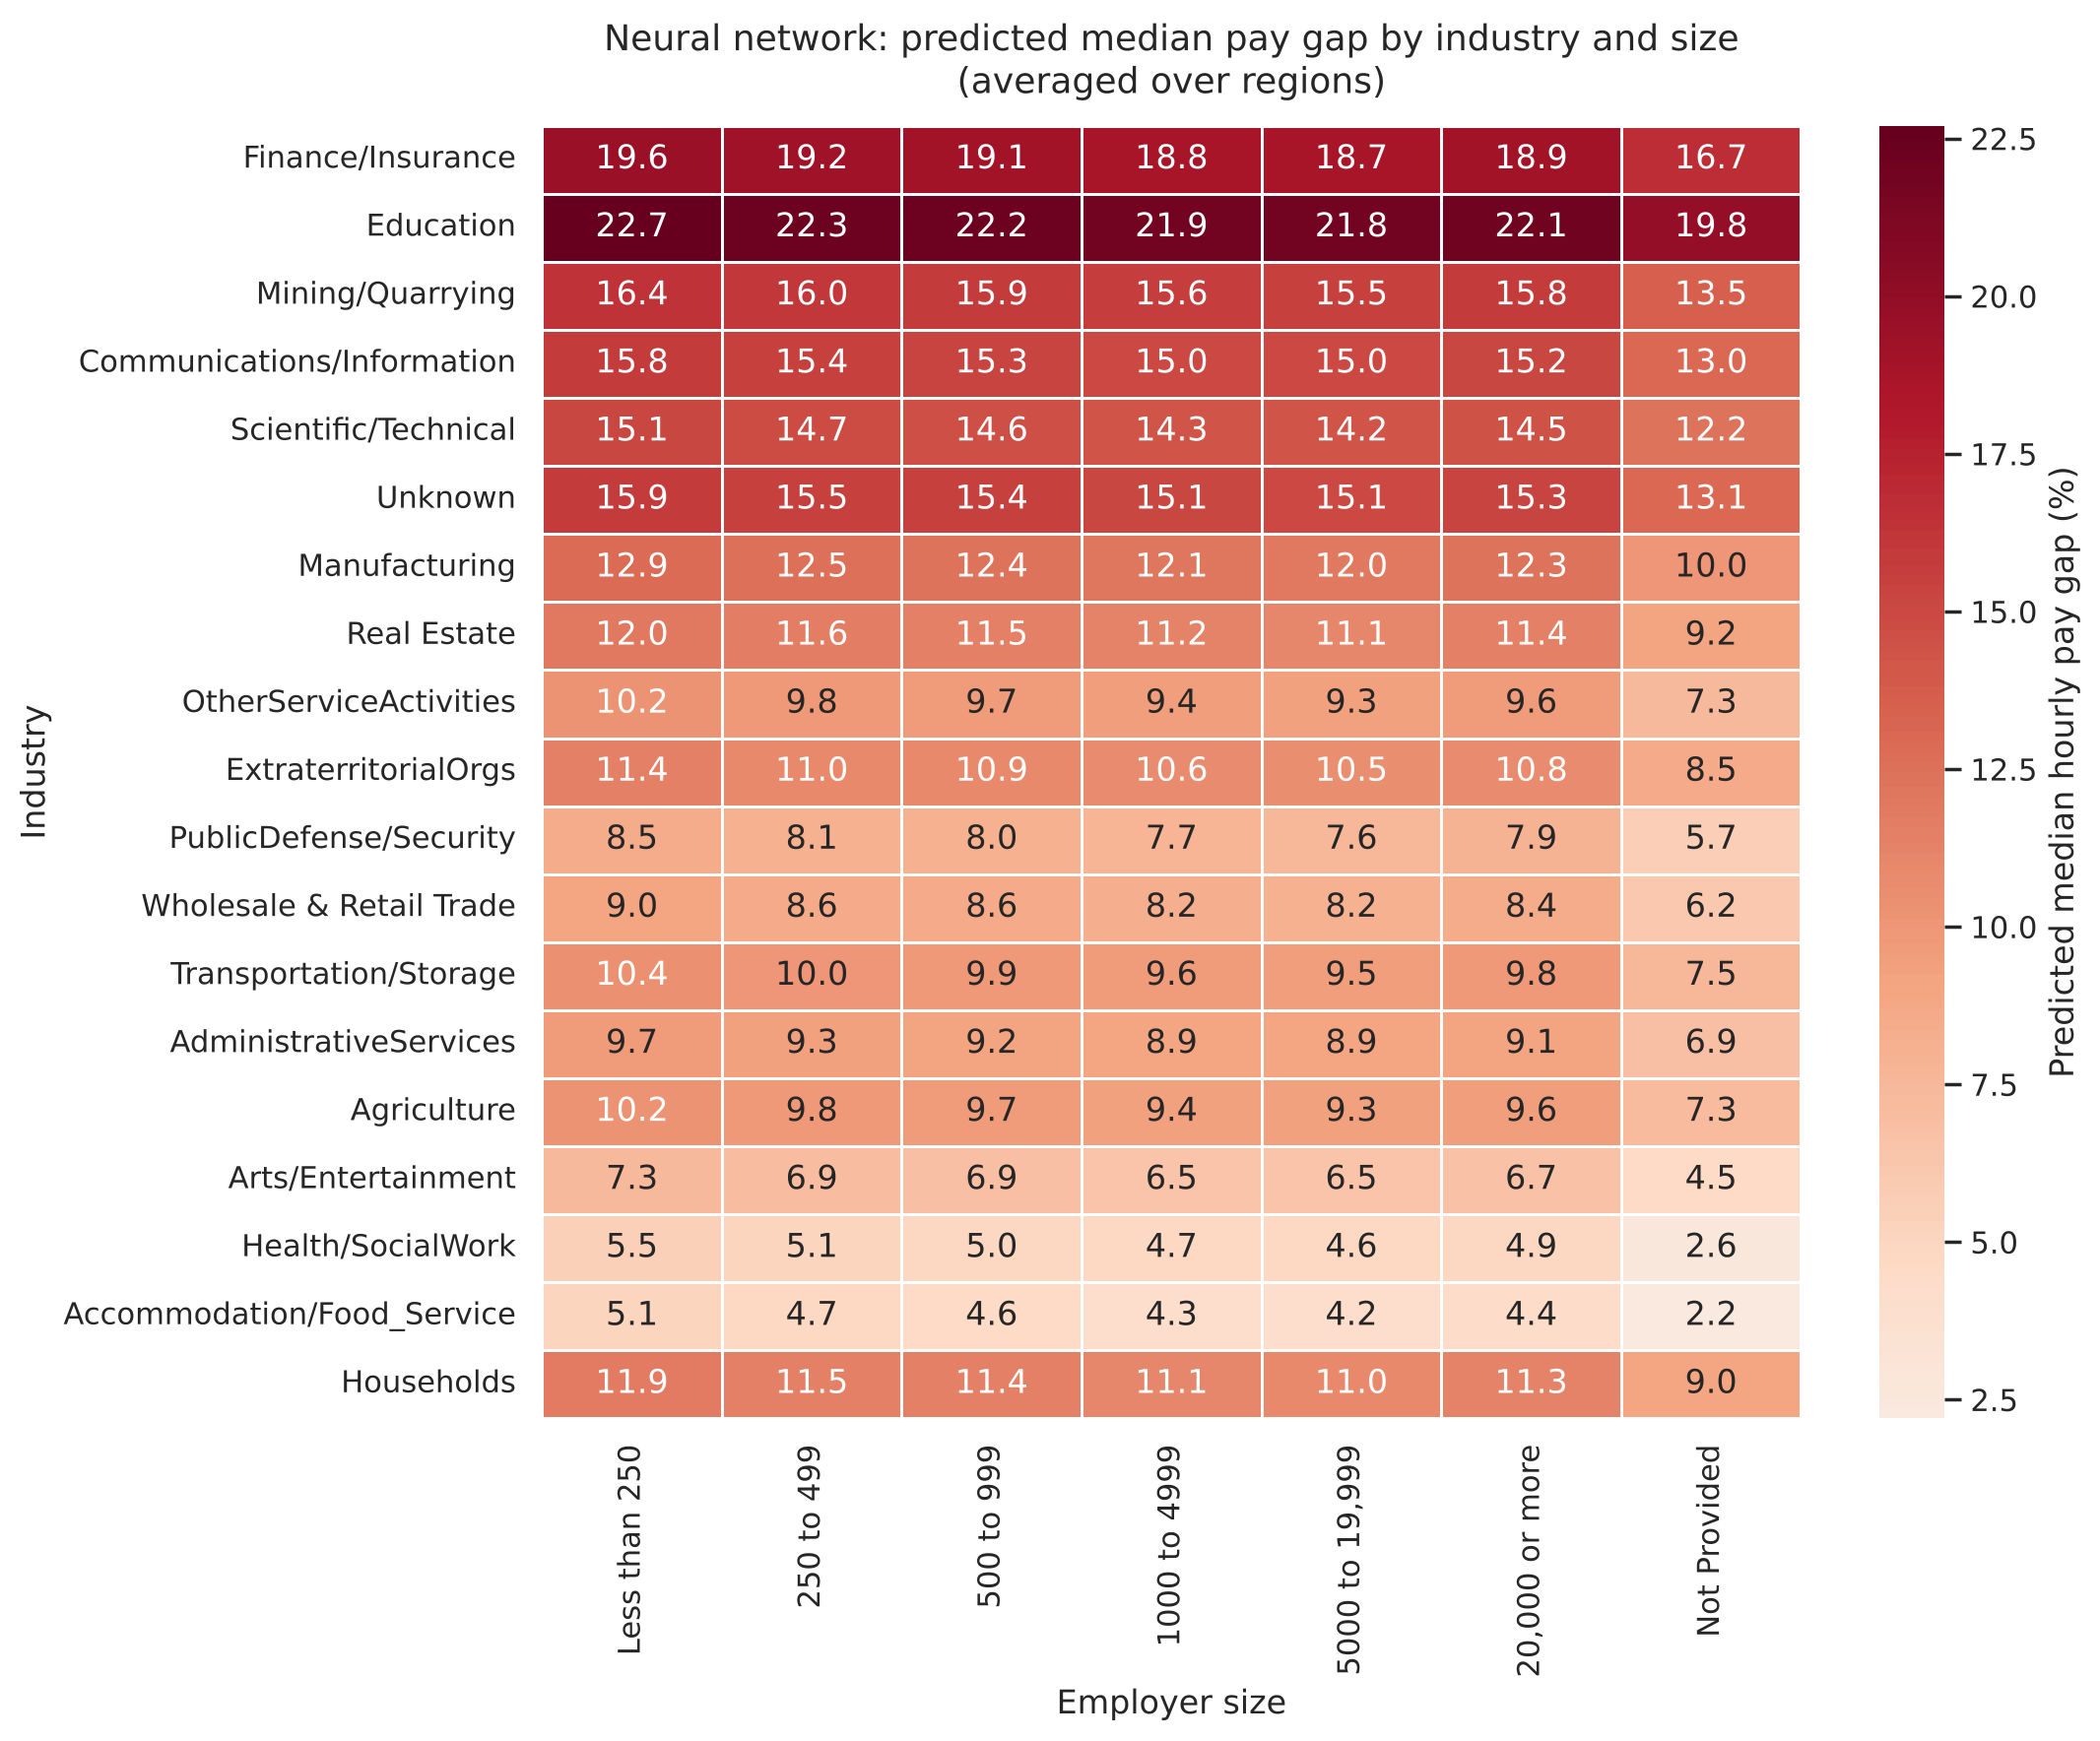

In [16]:
region_weights = X_train["Region"].value_counts(normalize=True)
grid_rows = pd.MultiIndex.from_product([industry_order, size_order, region_weights.index],
                                       names=["Industry", "Size", "Region"]).to_frame(index=False)
grid_rows = grid_rows[["Size", "Industry", "Region"]]
grid_rows["predicted"] = to_gap(final_nn.predict(grid_rows))
grid_rows["weight"] = grid_rows["Region"].map(region_weights)

predicted_table = (grid_rows.assign(wp=grid_rows["predicted"] * grid_rows["weight"])
                   .groupby(["Industry", "Size"])["wp"].sum()
                   .unstack().loc[industry_order, size_order])

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(predicted_table, annot=True, fmt=".1f", cmap="RdBu_r", center=0, linewidths=0.5,
            cbar_kws={"label": "Predicted median hourly pay gap (%)"}, ax=ax)
ax.grid(False)
ax.set_xlabel("Employer size")
ax.set_ylabel("Industry")
ax.set_title("Neural network: predicted median pay gap by industry and size\n(averaged over regions)",
             fontsize=13, pad=12)
plt.tight_layout()
plt.show()

In [17]:
# Predicted gap for any single company
def predict_gap(size, industry, region):
    row = pd.DataFrame([{"Size": size, "Industry": industry, "Region": region}])
    return round(float(to_gap(final_nn.predict(row))[0]), 1)

examples = pd.DataFrame([
    ("250 to 499", "Finance/Insurance", "Central London"),
    ("250 to 499", "Health/SocialWork", "Central London"),
    ("1000 to 4999", "Education", "Birmingham"),
    ("1000 to 4999", "Manufacturing", "Manchester"),
], columns=predictors)
examples["predicted gap (%)"] = [predict_gap(*r) for r in examples[predictors].itertuples(index=False)]
examples

,Size,Industry,Region,predicted gap (%)
0,250 to 499,Finance/Insurance,Central London,23.2
1,250 to 499,Health/SocialWork,Central London,9.1
2,1000 to 4999,Education,Birmingham,21.5
3,1000 to 4999,Manufacturing,Manchester,10.5


## 6. Findings

**Answer to the question:** given only an employer's size, industry and region, the best model (the neural network) predicts its median hourly gap with an average error (MAE) of about **10.5 percentage points** and an RMSE of **14.8 points**, and explains about **13%** of the variation in gaps (test R² 0.126).

**Test-set errors (percentage points)**

| Model | MAE | RMSE | Test R² |
|---|---|---|---|
| Training average (baseline) | 11.73 | 15.83 | 0.000 |
| Industry average (lookup) | 10.52 | 14.85 | 0.120 |
| Linear regression | 10.49 | 14.85 | 0.120 |
| kNN (k = 101) | 10.64 | 14.84 | 0.122 |
| **Neural network** | **10.49** | **14.80** | **0.126** |

RMSE is about 4 points above MAE for every model, which means a minority of employers are missed by a lot: those with very large gaps, or large gaps in women's favour.

1. **Industry drives almost all of the prediction.** Dropping industry lowers both models' CV R² by about 0.12, nearly everything they have. Predicted gaps run from about 4–5% in Accommodation/Food Service and Health/Social Work to about 19–22% in Finance/Insurance and Education.
2. **Region adds a little** (about 0.01 in R²), mostly because London areas have larger gaps.
3. **Size adds nothing.** Dropping it doesn't lower either model's score, and the predicted gap moves by less than 1 point across size bands within an industry.
4. **The models barely beat a simple lookup.** Predicting each employer's industry average already gives a test R² of 0.120. kNN (0.122), linear regression (0.120) and the neural network (0.126) are all close to that. With three categorical predictors there isn't much structure for a complex model to find.
5. **The neural network is the best model, but only just.** It is best on all three measures (R² 0.126, MAE 10.49, RMSE 14.80), but only by about 0.05 points of error over the industry-average lookup. It is very stable across starting weights.

**What this means for certification**
- Size, industry and region give a **fair benchmark**, not a verdict. A certification body can say "employers like you (same industry, size and region) have a predicted gap of about X%", and compare a company's actual gap with that.
- They **can't decide certification on their own:** an average error of 10.5 points means two employers with identical size, industry and region often have very different gaps. Certification should rest on each company's own reported gap.
- Industry is where to focus outreach. Finance/Insurance, Education, Mining and Communications have the highest predicted gaps whatever their size or region.

**Limitations**
- The models predict the **average** gap for a group, which runs a little above the typical (median) employer, because a minority of employers have very large gaps. For example, Health/Social Work's predicted gap (about 5%) is above its median employer's gap (about 1.5%).
- Small categories (Households, Extraterritorial Orgs, regions with a handful of employers) have unreliable predictions. Households has only 3 employers, so its predicted 11–12% gap is mostly a guess.
- These are associations, not causes: industry may stand in for the kinds of jobs and pay structures within it.